In [1]:
from finsent.data.split import load_splits
from finsent.models.baseline import build_tfidf_lr, build_dummy
from finsent.models.evaluate import evaluate, plot_confusion_matrix
import pandas as pd

In [2]:
train , val , test = load_splits()

In [3]:
model = build_tfidf_lr()
model.fit(train["text"], train["label"])


,steps,"[('tfidf', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [4]:
df=model.predict(val["text"])
df[:9]
df=pd.Series(df)
df.value_counts()

neutral     1097
positive     217
negative      96
Name: count, dtype: int64

In [5]:
dum_base=build_dummy()
dum_base.fit(train["text"], train["label"])

,strategy,'most_frequent'
,random_state,None
,constant,None


In [6]:
df2=dum_base.predict(val["text"])
df2[:9]
df2=pd.Series(df2)
df2.value_counts()


neutral    1410
Name: count, dtype: int64

In [7]:
vocab_size = len(model.named_steps["tfidf"].vocabulary_)

print(f"Total vocabulary size: {vocab_size:,}")


Total vocabulary size: 15,247


In [8]:
eval1 = evaluate(val["label"], df)
eval2 = evaluate(val["label"], df2)
print(eval1)
print(eval2)    

{'accuracy': 0.798581560283688, 'macro_f1': 0.6841068559183457, 'f1_negative': 0.5048543689320388, 'f1_neutral': 0.8754980079681275, 'f1_positive': 0.6719681908548708}
{'accuracy': 0.6460992907801418, 'macro_f1': 0.26166882091052707, 'f1_negative': 0.0, 'f1_neutral': 0.7850064627315813, 'f1_positive': 0.0}


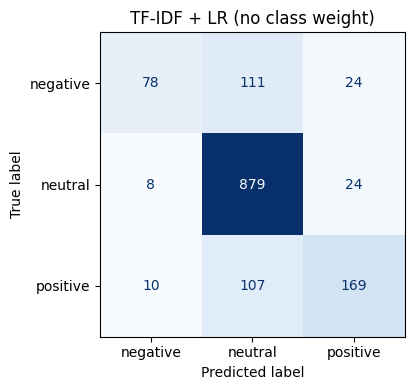

In [9]:
fig = plot_confusion_matrix(val["label"], df, "TF-IDF + LR (no class weight)")

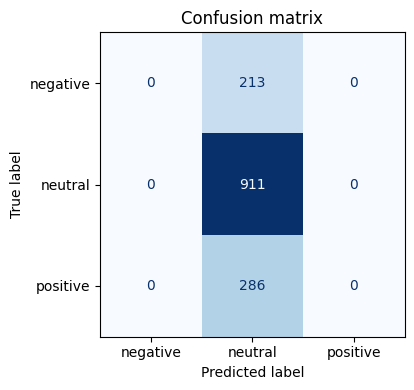

In [10]:
fig2= plot_confusion_matrix(val["label"], df2)